In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [57]:
from pathlib import Path
print("Current working directory:", Path.cwd())

Current working directory: d:\folder\MLOps-projects\bike-demand-predictor\notebooks


In [58]:
from pathlib import Path

DATA_PATH = Path("../data/raw/hour.csv")

print("File exists:", DATA_PATH.exists())
print("Resolved path:", DATA_PATH.resolve())

File exists: True
Resolved path: D:\folder\MLOps-projects\bike-demand-predictor\data\raw\hour.csv


In [59]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (17379, 17)


In [60]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [61]:
df.sample(5, random_state=42)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
12830,12831,2012-06-23,3,1,6,19,0,6,0,1,0.80,0.6970,0.27,0.1940,185,240,425
8688,8689,2012-01-02,1,1,1,20,1,1,0,1,0.24,0.2273,0.41,0.2239,5,83,88
7091,7092,2011-10-28,4,0,10,2,0,5,1,1,0.32,0.3030,0.66,0.2836,1,3,4
12230,12231,2012-05-29,2,1,5,19,0,2,1,1,0.78,0.7121,0.52,0.3582,69,457,526
431,432,2011-01-20,1,0,1,0,0,4,1,1,0.26,0.2273,0.56,0.3881,5,8,13


In [62]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Total observations:", df.size)

Rows: 17379
Columns: 17
Total observations: 295443


In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [64]:
df.dtypes

instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

In [65]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [66]:
df.isnull().sum().sort_values(ascending=False)

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [67]:
(df.isnull().mean() * 100).sort_values(ascending=False)

instant       0.0
dteday        0.0
season        0.0
yr            0.0
mnth          0.0
hr            0.0
holiday       0.0
weekday       0.0
workingday    0.0
weathersit    0.0
temp          0.0
atemp         0.0
hum           0.0
windspeed     0.0
casual        0.0
registered    0.0
cnt           0.0
dtype: float64

In [68]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [69]:
df.nunique().sort_values()

yr                2
holiday           2
workingday        2
season            4
weathersit        4
weekday           7
mnth             12
hr               24
windspeed        30
temp             50
atemp            65
hum              89
casual          322
dteday          731
registered      776
cnt             869
instant       17379
dtype: int64

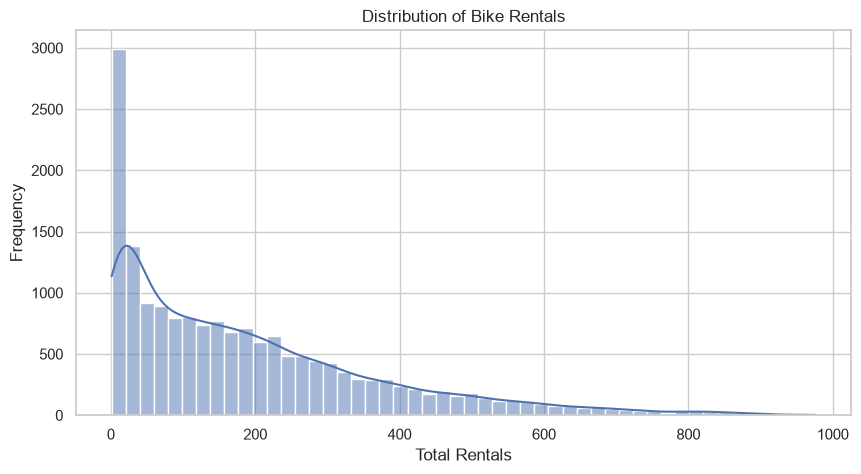

In [70]:
plt.figure(figsize=(10, 5))

sns.histplot(df["cnt"], bins=50, kde=True)

plt.title("Distribution of Bike Rentals")
plt.xlabel("Total Rentals")
plt.ylabel("Frequency")

plt.show()

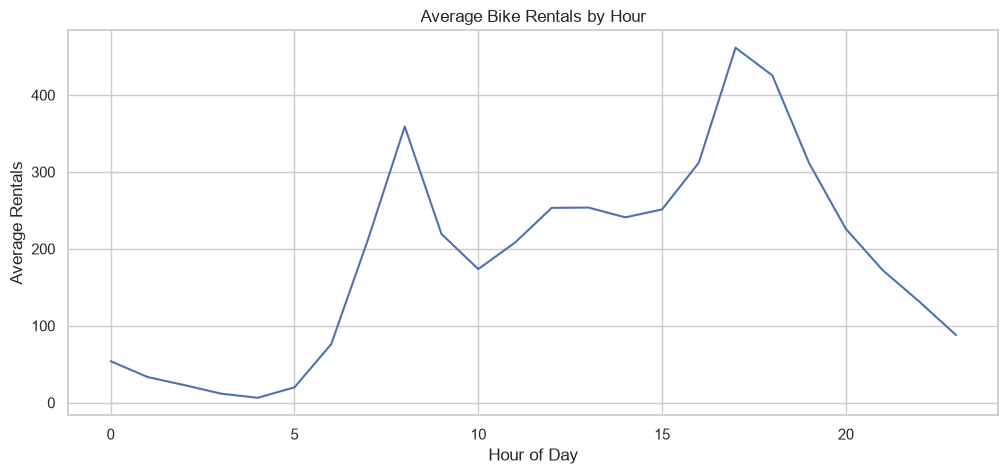

In [71]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=df, x="hr", y="cnt", errorbar=None)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")

plt.show()

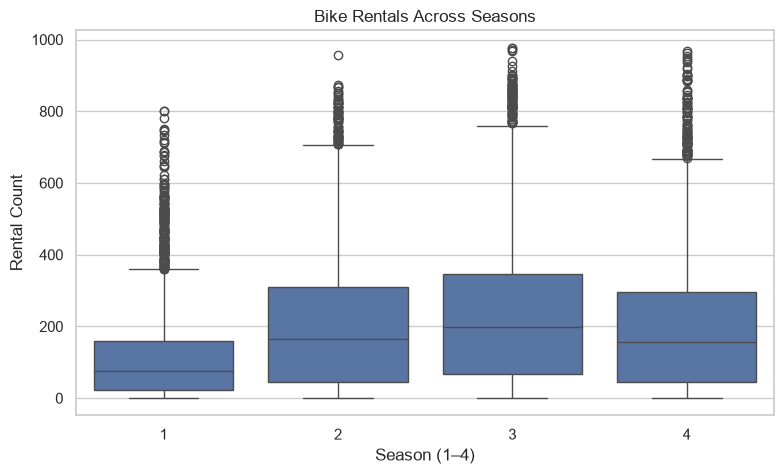

In [72]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="season", y="cnt")

plt.title("Bike Rentals Across Seasons")
plt.xlabel("Season (1–4)")
plt.ylabel("Rental Count")

plt.show()

In [73]:
hourly_avg = df.groupby("hr")["cnt"].mean()

print(hourly_avg.sort_values(ascending=False).head(5))

hr
17    461.452055
18    425.510989
8     359.011004
16    311.983562
19    311.523352
Name: cnt, dtype: float64


In [74]:
season_avg = df.groupby("season")["cnt"].mean()

print(season_avg.sort_values(ascending=False))

season
3    236.016237
2    208.344069
4    198.868856
1    111.114569
Name: cnt, dtype: float64


In [75]:
print("Skewness:", df["cnt"].skew())

Skewness: 1.277411603749058


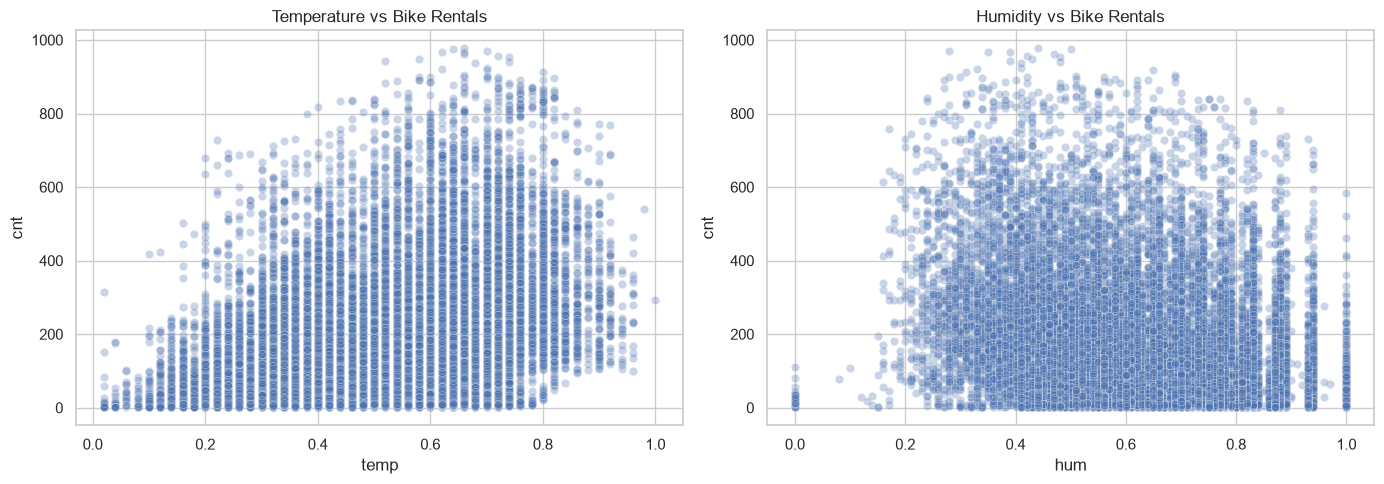

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="temp", y="cnt", alpha=0.3, ax=axes[0])
axes[0].set_title("Temperature vs Bike Rentals")

sns.scatterplot(data=df, x="hum", y="cnt", alpha=0.3, ax=axes[1])
axes[1].set_title("Humidity vs Bike Rentals")

plt.tight_layout()
plt.show()

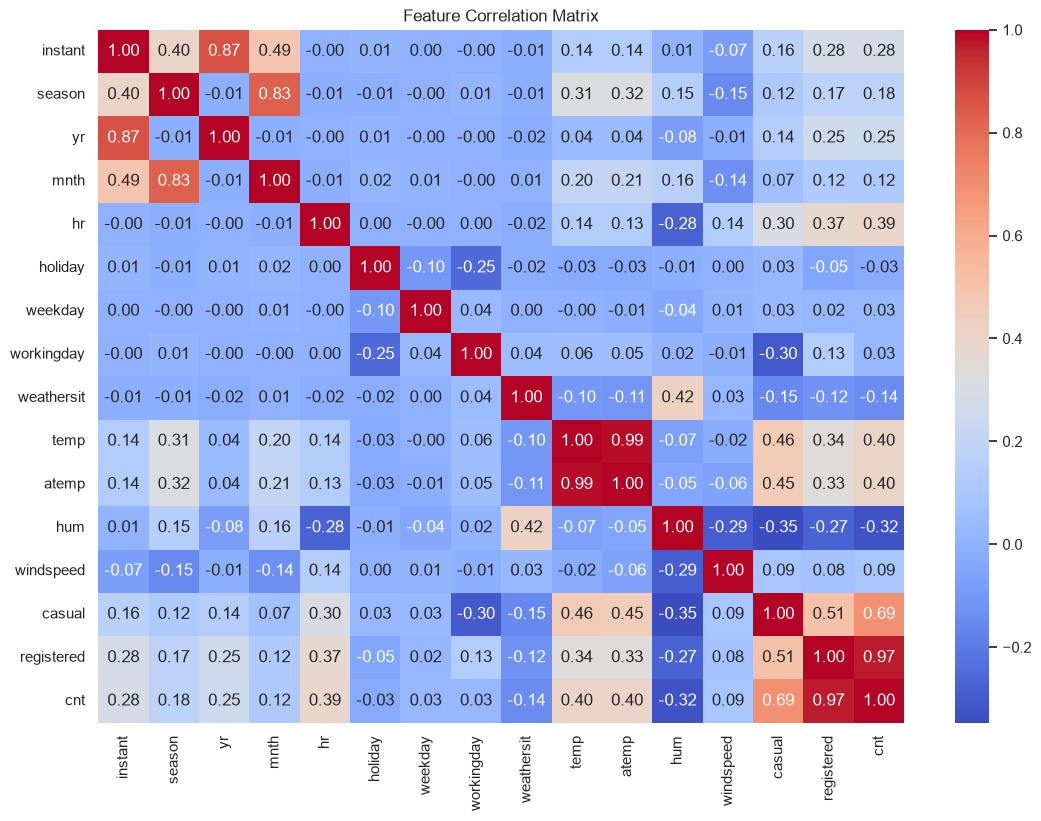

In [77]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Feature Correlation Matrix")
plt.show()

In [78]:
target = "cnt"

features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "hum",
    "windspeed"
]

X = df[features].copy()
y = df[target].copy()

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

display(X.head())
display(y.head())

Feature matrix: (17379, 11)
Target vector: (17379,)


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.81,0.0
1,1,0,1,1,0,6,0,1,0.22,0.80,0.0
2,1,0,1,2,0,6,0,1,0.22,0.80,0.0
3,1,0,1,3,0,6,0,1,0.24,0.75,0.0
4,1,0,1,4,0,6,0,1,0.24,0.75,0.0


0    16
1    40
2    32
3    13
4     1
Name: cnt, dtype: int64

In [79]:
print("First date:", df["dteday"].iloc[0])
print("Last date:", df["dteday"].iloc[-1])

print("\nIs dataset sorted chronologically?")
print(pd.to_datetime(df["dteday"]).is_monotonic_increasing)

First date: 2011-01-01
Last date: 2012-12-31

Is dataset sorted chronologically?
True


In [80]:
n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (12165, 11) (12165,)
Validation: (2607, 11) (2607,)
Testing: (2607, 11) (2607,)


In [81]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler
)
from sklearn.pipeline import Pipeline

In [82]:
def encode_hour(X):
    hour = X[:, 0]

    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)

    return np.column_stack([hour_sin, hour_cos])


hour_transformer = FunctionTransformer(
    encode_hour,
    validate=True
)

In [83]:
sample_hours = np.array([[0], [6], [12], [18], [23]])

print(hour_transformer.transform(sample_hours))

[[ 0.00000000e+00  1.00000000e+00]
 [ 1.00000000e+00  6.12323400e-17]
 [ 1.22464680e-16 -1.00000000e+00]
 [-1.00000000e+00 -1.83697020e-16]
 [-2.58819045e-01  9.65925826e-01]]


In [84]:
# Feature groups
numeric_features = ["temp", "hum", "windspeed"]

categorical_features = [
    "season",
    "mnth",
    "weekday",
    "weathersit"
]

cyclical_features = ["hr"]

binary_features = ["yr", "holiday", "workingday"]


# Individual pipelines
numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

cyclical_pipeline = Pipeline(steps=[
    ("hour_encoding", FunctionTransformer(
        encode_hour,
        validate=True
    ))
])


# Combine everything
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
        ("cyc", cyclical_pipeline, cyclical_features),
        ("bin", "passthrough", binary_features)
    ]
)

In [85]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (12165, 35)
Validation: (2607, 35)
Testing: (2607, 35)


In [86]:
print("Output type:", type(X_train_processed))
print("Data type:", X_train_processed.dtype)
print("First 5 rows:")
print(X_train_processed[:5])

Output type: <class 'numpy.ndarray'>
Data type: float64
First 5 rows:
[[-1.20994662  0.91282523 -1.56879573  1.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          1.          0.          0.          0.
   0.          1.          0.          0.          0.        ]
 [-1.31602645  0.86289169 -1.56879573  1.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          1.          0.          0.          0.
   0.25881905  0.96592583  0.          0.          0.        ]
 [-1.31602645  0.86289169 -1.56879573  1.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.       

In [87]:
print("Output type:", type(X_train_processed))
print("Output dtype:", X_train_processed.dtype)

print("\nShapes:")
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

print("\nFirst 5 rows:")
print(X_train_processed[:5])

Output type: <class 'numpy.ndarray'>
Output dtype: float64

Shapes:
Train: (12165, 35)
Validation: (2607, 35)
Test: (2607, 35)

First 5 rows:
[[-1.20994662  0.91282523 -1.56879573  1.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          1.          0.          0.          0.
   0.          1.          0.          0.          0.        ]
 [-1.31602645  0.86289169 -1.56879573  1.          0.          0.
   0.          1.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          1.          0.          0.          0.
   0.25881905  0.96592583  0.          0.          0.        ]
 [-1.31602645  0.86289169 -1.56879573  1.          0.          0.
   0. 

In [88]:
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

In [89]:
print(X_train_processed.dtype)
print(y_train.dtype)

float32
float32


In [90]:
import torch

In [91]:
X_train_tensor = torch.from_numpy(X_train_processed)
X_test_tensor = torch.from_numpy(X_test_processed)
X_val_tensor = torch.from_numpy(X_val_processed)


y_train_tensor = torch.from_numpy(y_train).reshape(-1,1)
y_test_tensor = torch.from_numpy(y_test).reshape(-1,1)
y_val_tensor = torch.from_numpy(y_val).reshape(-1,1)

In [92]:
print("Input shape: ",X_train_tensor.shape)
print("Target shape :",y_train_tensor.shape)

print("\nInput dtype: ", X_train_tensor.dtype)
print("Target dtype: ", y_train_tensor.dtype)

print("\nDevice:",X_train_tensor.device)

Input shape:  torch.Size([12165, 35])
Target shape : torch.Size([12165, 1])

Input dtype:  torch.float32
Target dtype:  torch.float32

Device: cpu


In [102]:
import torch.nn as nn

class BikeDemandANN(nn.Module):

    def __init__(self, input_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_features, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

In [103]:
model= BikeDemandANN(
    input_features = X_train_tensor.shape[1]
)
print(model)

BikeDemandANN(
  (network): Sequential(
    (0): Linear(in_features=35, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [104]:
criterion = nn.MSELoss()

In [105]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [106]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [107]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [108]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [109]:
for batch_X, batch_y in train_loader:
    print("Input batch:", batch_X.shape)
    print("Target batch:", batch_y.shape)
    break

print("Training batches:", len(train_loader))

Input batch: torch.Size([64, 35])
Target batch: torch.Size([64, 1])
Training batches: 191


In [113]:
model.train()

total_loss = 0

for batch_X, batch_y in train_loader:
    optimizer.zero_grad()

    predictions = model(batch_X)
    loss = criterion(predictions, batch_y)

    loss.backward()
    optimizer.step()

    total_loss += loss.item()

epoch_loss = total_loss / len(train_loader)

print("Training Loss:", epoch_loss)

Training Loss: 35837.422186886455


In [114]:
model = BikeDemandANN(input_features=35)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

sample_predictions = model(X_train_tensor[:64])

print("Prediction shape:", sample_predictions.shape)
print("Target shape:", y_train_tensor[:64].shape)

Prediction shape: torch.Size([64, 1])
Target shape: torch.Size([64, 1])


In [115]:
model.eval()

val_loss = 0

with torch.no_grad():
    for batch_X, batch_y in val_loader:

        predictions = model(batch_X)

        loss = criterion(predictions, batch_y)

        val_loss += loss.item()

val_loss /= len(val_loader)

print("Validation MSE:", val_loss)
print("Validation RMSE:", val_loss ** 0.5)

Validation MSE: 129033.96798780488
Validation RMSE: 359.21298415815215


In [117]:
import numpy as np

for name, data in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}")
    print("Mean:", np.mean(data))
    print("Std:", np.std(data))
    print("Min:", np.min(data))
    print("Max:", np.max(data))
    print("Median:", np.median(data))


Training
Mean: 159.93365
Std: 152.5732
Min: 1.0
Max: 957.0
Median: 119.0

Validation
Mean: 281.0414
Std: 223.23439
Min: 2.0
Max: 970.0
Median: 251.0

Test
Mean: 235.67741
Std: 215.10117
Min: 1.0
Max: 977.0
Median: 186.0


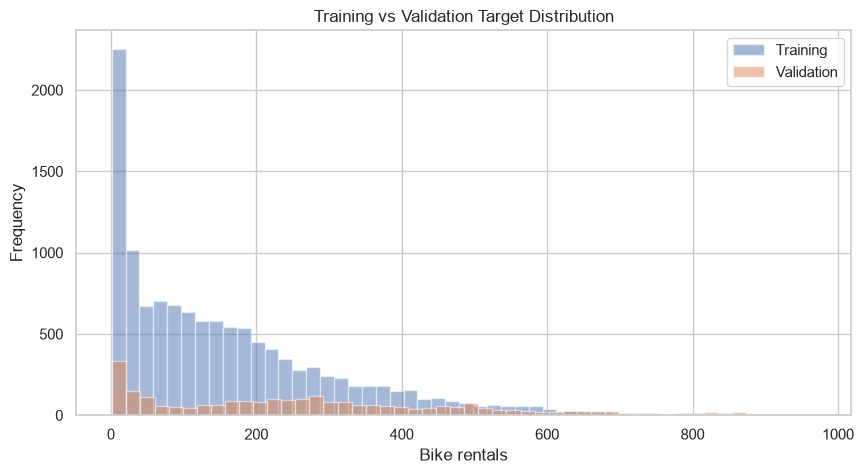

In [118]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(y_train, bins=50, alpha=0.5, label="Training")
plt.hist(y_val, bins=50, alpha=0.5, label="Validation")

plt.xlabel("Bike rentals")
plt.ylabel("Frequency")
plt.title("Training vs Validation Target Distribution")
plt.legend()
plt.show()